# JEDI Random Forest Baseline

**Goal:** train a tree-based classifier to predict whether a job should be applied to.

Target:

```text
applied = yes / no
```

This notebook uses only production-available job features. It excludes all personal preference score columns because those are annotation labels/signals, not fields we naturally have for future scraped jobs.


## What Random Forest Is

A random forest is a collection of decision trees.

A single decision tree learns rules like:

```text
if seniority is senior -> likely no
if role is backend and location is Bengaluru -> more likely yes
if remote + senior + global -> likely no
```

A random forest trains many trees on slightly different samples/features and averages their predictions. This usually makes it more stable than one tree.

Why it is useful after logistic regression:

- captures non-linear rules
- captures feature interactions naturally
- does not require numeric scaling
- can output feature importances

Main risk: with small data, it can overfit if trees are too deep.

In [32]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    log_loss, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42
DATA_PATH = Path("../../data/jedi_master_prepared.csv")


## 1. Load Dataset And Target

We map:

```text
yes -> 1
no  -> 0
```

In [33]:
df = pd.read_csv(DATA_PATH)
df["applied_clean"] = df["applied"].astype(str).str.strip().str.lower()
df["target_applied"] = df["applied_clean"].map({"yes": 1, "no": 0})

if df["target_applied"].isna().any():
    raise ValueError(df.loc[df["target_applied"].isna(), "applied"].value_counts(dropna=False))

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df[["applied", "target_applied"]].value_counts().rename("count").reset_index())
display(df.head(3))

Rows: 331 | Columns: 53


,applied,target_applied,count
0,no,0,205
1,yes,1,126


,row_id,source_platform,source_type,scraped_at,can_apply_now,company_name,company_match_score,role_title,role_title_preference_score,role_family,role_family_preference_score,seniority,seniority_profile_fit_score,location,location_profile_fit_score,work_mode,work_mode_fit_score,employment_type,experience_min_years,experience_max_years,experience_profile_fit_score,skills_or_requirements,skills_profile_fit_score,salary_min,salary_max,salary_profile_fit_score,freshness,overall_preference_score,preference_reason,applied,apply_url,skills_or_requirements_original,skills_array,has_skills_or_requirements,skills_imputation_type,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,is_bengaluru,is_gurgaon_ncr,is_india,experience_min_bucket,salary_midpoint,salary_available,near_duplicate_key,company_name_standard,role_title_standard,applied_clean,target_applied
0,1,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Nirmata,4,"Software Engineer Intern, India",5,Backend / Cloud,4,intern,5,"Bangalore, Hybrid",4,Hybrid,5,internship,0.0,1.0,5.0,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,2,1200000,1200000,5,Not visible,3,"Intern role is fine, everything is good but the requirements state Kubernetes, observability tools, promethus and Go which dont match wi...",no,https://job-boards.greenhouse.io/nirmata/jobs/5040355008,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,"[""go"",""java"",""microservices"",""kubernetes"",""prometheus"",""timescale"",""reliability"",""automation""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,1200000,True,nirmata|software_engineer_intern_india|bengaluru,nirmata,software_engineer_intern_india,no,0
1,2,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,CloudSEK,5,SDE - Backend - Intern,5,Backend,5,intern,5,"Bengaluru, Karnataka, India",4,Hybrid,5,internship,0.0,1.0,5.0,Backend engineering; cybersecurity product; APIs; databases likely,4,800000,900000,4,Not visible,4,"Backend intern in Bengaluru; very relevant for fresher profile, salary is a little less and location bengaluru",yes,https://job-boards.greenhouse.io/cloudsek/jobs/5766402004,Backend engineering; cybersecurity product; APIs; databases likely,"[""backend engineering"",""cybersecurity product"",""apis"",""databases likely""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,850000,True,cloudsek|sde_backend_intern|bengaluru,cloudsek,sde_backend_intern,yes,1
2,3,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Anaplan,5,Associate Software Engineer,5,Backend / Fullstack,5,entry_level,5,"Gurugram, India",5,unknown,5,full_time,0.0,2.0,5.0,Software engineering; AI-infused platform; SaaS; cloud; planning systems,5,500000,700000,2,Not visible,3,Associate level in Gurgaon; high-quality company and location fitbut salary is quite less and the bad factor,yes,https://job-boards.greenhouse.io/anaplan/jobs/8511489002,Software engineering; AI-infused platform; SaaS; cloud; planning systems,"[""software engineering"",""ai-infused platform"",""saas"",""cloud"",""planning systems""]",True,original,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,False,True,True,0,600000,True,anaplan|associate_software_engineer|delhi_ncr,anaplan,associate_software_engineer,yes,1


## 2. Feature Policy

Use job facts and standardized derived fields.

Do **not** use personal score columns here:

- `role_title_preference_score`
- `seniority_profile_fit_score`
- `skills_profile_fit_score`
- `overall_preference_score`

Those will be used later when we build score prediction models.

In [34]:
score_columns = [c for c in df.columns if c.endswith("_score")]

drop_columns = sorted(set([
    "row_id", "apply_url", "source_platform", "source_type", "scraped_at",
    "applied", "applied_clean", "target_applied", "overall_preference_score",
    "preference_reason", "near_duplicate_key", "company_name_standard", "role_title_standard",
] + score_columns))

text_source_columns = ["company_name", "role_title", "role_family", "seniority", "location", "skills_or_requirements", "skills_array"]
categorical_features = ["can_apply_now", "role_family_standard", "seniority_standard", "employment_type_standard", "work_mode_standard", "city_standard", "country_standard", "location_bucket", "experience_min_bucket", "skills_imputation_type", "freshness"]
numeric_features = ["experience_min_years", "salary_min", "salary_max", "salary_midpoint"]
boolean_features = ["has_skills_or_requirements", "is_bengaluru", "is_gurgaon_ncr", "is_india", "salary_available"]

feature_plan = pd.DataFrame({
    "feature": text_source_columns + categorical_features + numeric_features + boolean_features,
    "group": ["text"] * len(text_source_columns) + ["categorical"] * len(categorical_features) + ["numeric"] * len(numeric_features) + ["boolean"] * len(boolean_features),
})
display(feature_plan)
display(pd.DataFrame({"dropped_column": [c for c in drop_columns if c in df.columns]}))

,feature,group
0,company_name,text
1,role_title,text
2,role_family,text
3,seniority,text
4,location,text
5,skills_or_requirements,text
6,skills_array,text
7,can_apply_now,categorical
8,role_family_standard,categorical
9,seniority_standard,categorical


,dropped_column
0,applied
1,applied_clean
2,apply_url
3,company_match_score
4,company_name_standard
5,experience_profile_fit_score
6,location_profile_fit_score
7,near_duplicate_key
8,overall_preference_score
9,preference_reason


## 3. Build Modeling Table

Random forest can work with one-hot categories and TF-IDF text features. We still combine all text into `job_text`.

In [35]:
model_df = df.copy()

for col in text_source_columns:
    model_df[col] = model_df[col].fillna("").astype(str)

model_df["job_text"] = (
    model_df["company_name"] + " " + model_df["role_title"] + " " + model_df["role_family"] + " "
    + model_df["seniority"] + " " + model_df["location"] + " "
    + model_df["skills_or_requirements"] + " " + model_df["skills_array"]
)

def bool_to_int(value):
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}: return 1
    if text in {"false", "0", "no", "n"}: return 0
    return np.nan

for col in boolean_features:
    model_df[col] = model_df[col].map(bool_to_int)
for col in numeric_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

feature_columns = ["job_text"] + categorical_features + numeric_features + boolean_features
X = model_df[feature_columns].copy()
y = model_df["target_applied"].astype(int)

display(X.head(3))

,job_text,can_apply_now,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,experience_min_bucket,skills_imputation_type,freshness,experience_min_years,salary_min,salary_max,salary_midpoint,has_skills_or_requirements,is_bengaluru,is_gurgaon_ncr,is_india,salary_available
0,"Nirmata Software Engineer Intern, India Backend / Cloud intern Bangalore, Hybrid Go; Java; microservices; Kubernetes; Prometheus; TimeSc...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,1200000,1200000,1200000,1,1,0,1,1
1,"CloudSEK SDE - Backend - Intern Backend intern Bengaluru, Karnataka, India Backend engineering; cybersecurity product; APIs; databases l...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,800000,900000,850000,1,1,0,1,1
2,"Anaplan Associate Software Engineer Backend / Fullstack entry_level Gurugram, India Software engineering; AI-infused platform; SaaS; clo...",Yes,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,0,original,Not visible,0.0,500000,700000,600000,1,0,1,1,1


## 4. Train/Test Split And Class Distribution

We use a random split with `stratify=y` so train and test have similar yes/no balance.

In [36]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

def class_distribution(labels, name):
    out = labels.value_counts().rename_axis("class").reset_index(name="count")
    out["share"] = out["count"] / len(labels)
    out["set"] = name
    return out[["set", "class", "count", "share"]]

display(pd.concat([class_distribution(y_train, "train"), class_distribution(y_test, "test")], ignore_index=True))

,set,class,count,share
0,train,0,164,0.621212
1,train,1,100,0.378788
2,test,0,41,0.611940
3,test,1,26,0.388060


## 5. Preprocessing Pipeline

Differences from logistic regression:

- numeric scaling is not necessary for random forest
- one-hot encoding still helps categorical variables
- TF-IDF still converts text into numeric features

In [37]:
numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=3)),
])

text_vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=800)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features + boolean_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("text", text_vectorizer, "job_text"),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## 6. Train Random Forest

Important parameters:

- `n_estimators`: number of trees
- `max_depth`: maximum tree depth; smaller reduces overfitting
- `min_samples_leaf`: minimum rows in a leaf; higher smooths predictions
- `class_weight`: handles yes/no imbalance
- `random_state`: reproducibility

In [38]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

model = Pipeline(steps=[("preprocess", preprocessor), ("classifier", rf)])
model.fit(X_train, y_train)
print("Random forest trained.")
model

Random forest trained.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diffe

In [44]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score
import pandas as pd
import numpy as np

# Use stratified CV because target is imbalanced-ish: 205 no, 126 yes
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_distributions = {
    # Random Forest size
    "classifier__n_estimators": [200, 400, 600, 800],

    # Tree complexity
    "classifier__max_depth": [4, 6, 8, 12, None],

    # Regularization: bigger leaf = less overfitting
    "classifier__min_samples_leaf": [1, 2, 3, 5, 8, 10],

    # Split control
    "classifier__min_samples_split": [2, 5, 10, 20],

    # Number of features considered at each split
    "classifier__max_features": ["sqrt", "log2", 0.3, 0.5, None],

    # Class imbalance handling
    "classifier__class_weight": ["balanced", "balanced_subsample", None],

    # Optional: tune text vectorizer too
    "preprocess__text__max_features": [400, 800, 1200, 1600],
    "preprocess__text__min_df": [1, 2, 3],
    "preprocess__text__ngram_range": [(1, 1), (1, 2)],
}

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_distributions,
    n_iter=40,
    scoring={
        "f1": "f1",
        "balanced_accuracy": "balanced_accuracy",
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
    },
    refit="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    random_state=RANDOM_STATE,
    return_train_score=True
)

search.fit(X_train, y_train)

print("Best CV score:", search.best_score_)
print("Best params:")
search.best_params_

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best CV score: 0.9013851374300771
Best params:


{'preprocess__text__ngram_range': (1, 2),
 'preprocess__text__min_df': 3,
 'preprocess__text__max_features': 400,
 'classifier__n_estimators': 400,
 'classifier__min_samples_split': 2,
 'classifier__min_samples_leaf': 2,
 'classifier__max_features': 0.5,
 'classifier__max_depth': 4,
 'classifier__class_weight': 'balanced_subsample'}

## 7. Evaluate

Random forest gives probabilities using `predict_proba`, so we can evaluate ranking quality too.

In [39]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision_yes": precision_score(y_test, y_pred, zero_division=0),
    "recall_yes": recall_score(y_test, y_pred, zero_division=0),
    "f1_yes": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "average_precision": average_precision_score(y_test, y_proba),
    "log_loss": log_loss(y_test, y_proba),
    "brier_score": brier_score_loss(y_test, y_proba),
}
display(pd.DataFrame([metrics]).T.rename(columns={0: "score"}))
print(classification_report(y_test, y_pred, target_names=["no", "yes"], zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["actual_no", "actual_yes"], columns=["pred_no", "pred_yes"]))

,score
accuracy,0.910448
balanced_accuracy,0.898687
precision_yes,0.916667
recall_yes,0.846154
f1_yes,0.880000
roc_auc,0.940901
average_precision,0.917822
log_loss,0.350877
brier_score,0.097800


              precision    recall  f1-score   support

          no       0.91      0.95      0.93        41
         yes       0.92      0.85      0.88        26

    accuracy                           0.91        67
   macro avg       0.91      0.90      0.90        67
weighted avg       0.91      0.91      0.91        67



,pred_no,pred_yes
actual_no,39,2
actual_yes,4,22


## 8. Threshold Table

Use this to decide how aggressive JEDI should be when recommending jobs.

,threshold,predicted_yes_count,precision_yes,recall_yes,f1_yes,balanced_accuracy
0,0.20,50,0.500000,0.961538,0.657895,0.675891
1,0.25,39,0.641026,0.961538,0.769231,0.810038
2,0.30,34,0.735294,0.961538,0.833333,0.871013
3,0.35,28,0.821429,0.884615,0.851852,0.881332
4,0.40,24,0.916667,0.846154,0.880000,0.898687
5,0.45,24,0.916667,0.846154,0.880000,0.898687
6,0.50,24,0.916667,0.846154,0.880000,0.898687
7,0.55,22,0.909091,0.769231,0.833333,0.860225
8,0.60,22,0.909091,0.769231,0.833333,0.860225
9,0.65,19,0.947368,0.692308,0.800000,0.833959


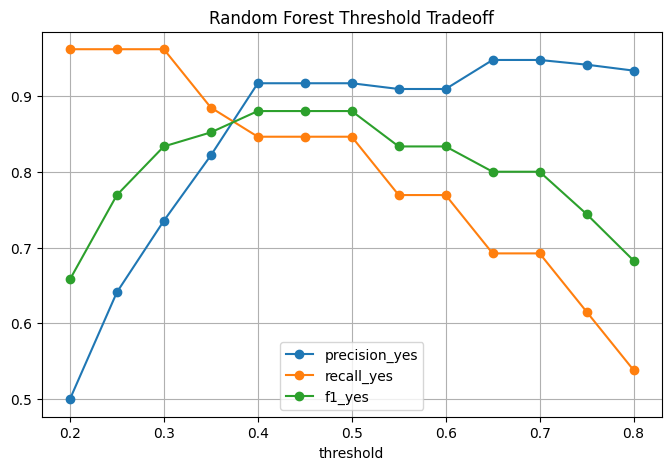

In [40]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "predicted_yes_count": int(pred.sum()),
        "precision_yes": precision_score(y_test, pred, zero_division=0),
        "recall_yes": recall_score(y_test, pred, zero_division=0),
        "f1_yes": f1_score(y_test, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.plot(x="threshold", y=["precision_yes", "recall_yes", "f1_yes"], marker="o", figsize=(8, 5), grid=True)
plt.title("Random Forest Threshold Tradeoff")
plt.show()

## 9. Cross-Validation

A single split can be noisy, so we compare performance across 5 stratified folds.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}
cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
cv_summary = []
for key, values in cv_results.items():
    if key.startswith("test_"):
        cv_summary.append({"metric": key.replace("test_", ""), "mean": np.mean(values), "std": np.std(values), "fold_scores": np.round(values, 3)})
display(pd.DataFrame(cv_summary).sort_values("metric"))

,metric,mean,std,fold_scores
0,accuracy,0.876210,0.027340,"[0.851, 0.879, 0.924, 0.879, 0.848]"
6,average_precision,0.898105,0.043713,"[0.896, 0.894, 0.965, 0.908, 0.828]"
1,balanced_accuracy,0.854402,0.035775,"[0.822, 0.863, 0.916, 0.856, 0.816]"
4,f1,0.822543,0.044481,"[0.783, 0.833, 0.898, 0.826, 0.773]"
2,precision,0.897146,0.015580,"[0.9, 0.87, 0.917, 0.905, 0.895]"
3,recall,0.762462,0.073419,"[0.692, 0.8, 0.88, 0.76, 0.68]"
5,roc_auc,0.922897,0.025854,"[0.906, 0.92, 0.97, 0.925, 0.894]"


## 10. Feature Importance

Random forest exposes `feature_importances_`.

Caution: importances can be biased toward high-cardinality or high-frequency features, but they are still useful for a first inspection.

,feature,importance
0,numeric__experience_min_years,0.066294
66,categorical__experience_min_bucket_0,0.049694
1,numeric__salary_min,0.047997
3,numeric__salary_midpoint,0.044474
2,numeric__salary_max,0.042582
24,categorical__seniority_standard_intern,0.020074
772,text__senior,0.018864
7,numeric__is_india,0.018440
328,text__engineer,0.016041
318,text__early,0.015730


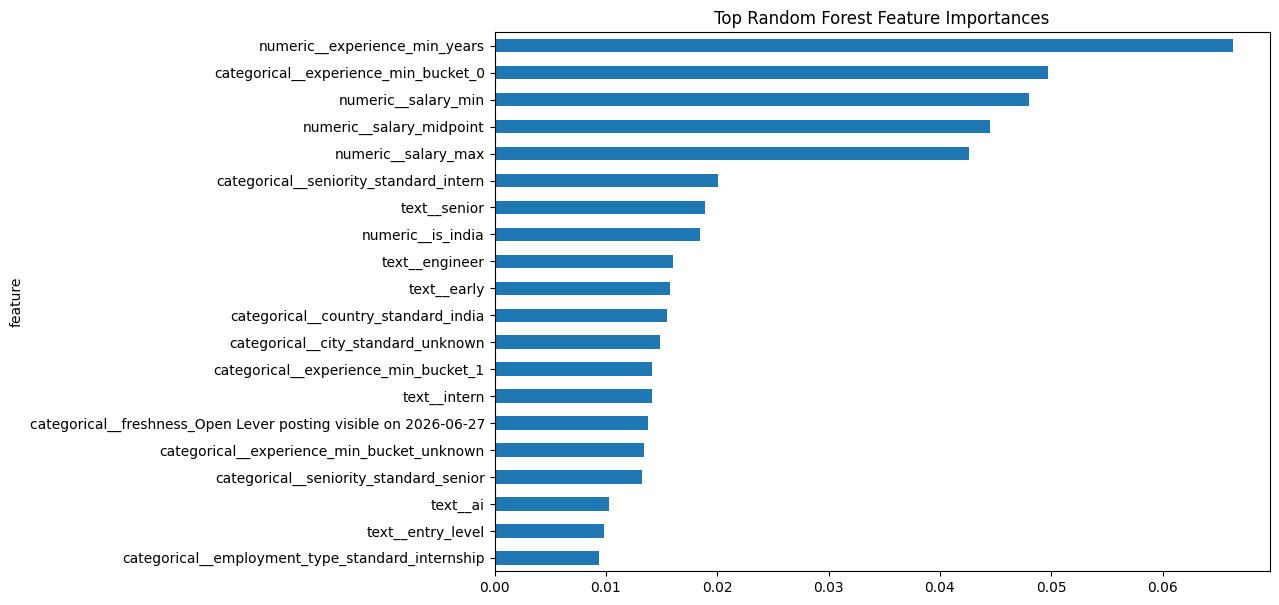

In [42]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
importances = model.named_steps["classifier"].feature_importances_
importance_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
display(importance_df.head(30))

importance_df.head(20).sort_values("importance").plot.barh(x="feature", y="importance", figsize=(10, 7), legend=False)
plt.title("Top Random Forest Feature Importances")
plt.show()

## 11. Parameter Options

Useful Random Forest parameters:

| Parameter | What it controls |
|---|---|
| `n_estimators` | number of trees |
| `max_depth` | tree depth; lower can reduce overfitting |
| `min_samples_leaf` | minimum rows per leaf; higher smooths predictions |
| `max_features` | how many features each split considers |
| `class_weight` | class imbalance handling |

Next experiments:

```python
max_depth=[4, 6, 8, None]
min_samples_leaf=[1, 2, 5]
n_estimators=[200, 400, 800]
```

In [43]:
review_cols = ["company_name", "role_title", "role_family_standard", "seniority_standard", "location_bucket", "work_mode_standard", "employment_type_standard", "skills_or_requirements"]
test_review = df.loc[X_test.index, review_cols + ["applied"]].copy()
test_review["actual_applied_binary"] = y_test.values
test_review["predicted_applied_binary"] = y_pred
test_review["applied_probability"] = y_proba
test_review["error_type"] = np.select(
    [(test_review["actual_applied_binary"] == 1) & (test_review["predicted_applied_binary"] == 0), (test_review["actual_applied_binary"] == 0) & (test_review["predicted_applied_binary"] == 1)],
    ["false_negative", "false_positive"],
    default="correct",
)
OUTPUT_PATH = Path("../../data/jedi_random_forest_test_predictions.csv")
test_review.sort_values("applied_probability", ascending=False).to_csv(OUTPUT_PATH, index=False)
print(f"Saved: {OUTPUT_PATH}")
display(test_review.sort_values("applied_probability", ascending=False).head(15))

Saved: data\jedi_random_forest_test_predictions.csv


,company_name,role_title,role_family_standard,seniority_standard,location_bucket,work_mode_standard,employment_type_standard,skills_or_requirements,applied,actual_applied_binary,predicted_applied_binary,applied_probability,error_type
317,Funding Societies | Modalku Group,Product Security Intern,other,intern,india_remote,remote,internship,Product security; Generative AI for security workflows; autonomous pentesting frameworks; secure SDLC; engineering culture,yes,1,1,0.899404,correct
172,360customizer,Backend Engineer,backend,junior,pune,onsite,full_time,backend fundamentals; rest apis; databases; sql; git; debugging; code quality; team collaboration,yes,1,1,0.890793,correct
260,Wahed,Join Our Internship Program,other,intern,mumbai,hybrid,internship,Internship program; fintech product; engineering/product exposure; learning role,yes,1,1,0.874632,correct
328,Naukri Search Seed - Noida,Frontend Developer Fresher,frontend,entry_level,delhi_ncr,onsite,full_time,React; JavaScript; HTML; CSS; TypeScript; responsive UI; Git,yes,1,1,0.862855,correct
286,TopGrep Tech,Software Engineer Intern to hire,fullstack,intern,bengaluru,onsite,internship,JavaScript; ReactJS; MySQL/Mongo/PostgreSQL; Azure; AI; Docker; Jenkins; Kubernetes; DataScience; ML/Ops,yes,1,1,0.855850,correct
258,Weekday,GTM Engineer,fullstack,entry_level,bengaluru,onsite,full_time,Automation; scripting; integrations; AI tools; product workflows; light fullstack,yes,1,1,0.855626,correct
4,Energy Exemplar,Associate Software Engineer - Python,backend,entry_level,bengaluru,unknown,full_time,Python; algorithms; product development; possible data/optimization systems,yes,1,1,0.852876,correct
202,Patronus,Full stack Engineer (AI & Data Pipelines),fullstack,junior,bengaluru,onsite,full_time,javascript; react; node.js; rest apis; databases; git; deployment basics; llms; agentic ai; sql; data pipelines; security fundamentals; ...,yes,1,1,0.852689,correct
315,Origin,CVAT Annotation Intern,ml_ai,intern,bengaluru,onsite,internship,CVAT; data annotation; machine learning data; AI delivery; computer vision datasets,no,0,1,0.847417,false_positive
327,Naukri Search Seed - Gurgaon,Backend Developer 0-2 Years,backend,entry_level,delhi_ncr,onsite,full_time,Backend APIs; Node.js/Python/Java; SQL/NoSQL; Git; REST; debugging,yes,1,1,0.842123,correct


## 12. Student Deep Dive: How To Read This Random Forest Notebook

This section explains the notebook as a learner, not just as code. Random forest is a useful comparison against logistic regression because it can learn non-linear rules such as "entry-level backend in Bengaluru is good, but senior backend with high experience is not".

### What random forest is doing

A decision tree asks a sequence of yes/no questions about the features. Example: is `experience_min_years` low? is `seniority_standard` intern? does the text contain backend? A random forest trains many such trees on slightly different samples and feature subsets, then averages their votes. This usually makes it more stable than one decision tree.

Compared with logistic regression, random forest does not learn one clean coefficient per feature. It learns many split rules. That makes it stronger for interactions but weaker for explanation.

### Why each preprocessing step exists

- `target_applied` is the numeric version of `applied`: yes becomes 1, no becomes 0.
- The preference score columns are dropped because they are human judgment columns. If they stayed, the model would partially learn your annotation values instead of learning from the job itself.
- `source_platform` and `source_type` are dropped so the model does not overfit to where a job came from.
- `job_text` is created by joining company, title, role family, seniority, location, and skills. This gives the model a broad text signal from the job card.
- Numeric features are imputed because sklearn models cannot use missing numeric values directly. For random forest, we do not need `StandardScaler`; trees split by thresholds and are not sensitive to units the same way logistic regression is.
- Categorical columns are one-hot encoded. A tree cannot split directly on raw strings like `backend` or `hybrid`, so each category becomes a 0/1 column.
- `handle_unknown='ignore'` allows future job categories to appear without crashing the pipeline.
- `min_frequency=3` reduces one-row category noise. This matters because rare values can make a tree memorize instead of generalize.
- TF-IDF converts `job_text` into numeric word and phrase features. A forest can use these columns as split signals.
- `Pipeline` keeps preprocessing and model training together, which is important for train/test split and cross-validation hygiene.
- `RandomForestClassifier(n_estimators=400)` trains 400 trees. More trees usually reduce variance but cost more time.
- `min_samples_leaf=2` prevents leaves with only one row. This is a small anti-overfitting guard.
- `class_weight='balanced_subsample'` adjusts each tree so the minority yes class is not ignored.

### How to read the metrics

- Confusion matrix: this run produced `39 true no`, `2 false yes`, `4 false no`, and `22 true yes`. The forest was slightly more conservative than logistic regression: fewer false positives, more missed yes jobs.
- Accuracy: `0.910`, same as logistic on this split.
- Balanced accuracy: `0.899`, slightly below logistic because yes recall is lower.
- Precision for yes: `0.917`. When the forest says apply, it is usually right.
- Recall for yes: `0.846`. It misses more apply-worthy jobs than logistic.
- F1 for yes: `0.880`, good but not the best among the notebooks.
- ROC-AUC: `0.933`, strong ranking ability.
- Average precision: `0.899`, strong for producing a ranked shortlist.
- Log loss and Brier score are probability-quality metrics. Random forest probabilities are often less smooth than logistic probabilities, so do not blindly trust them as calibrated probabilities.

### Interpreting this run

The forest is good, but its personality is different from logistic regression. It is stricter. It produced only 2 false positives, which means it avoids recommending many jobs you labeled no. But it also produced 4 false negatives, meaning it missed 4 jobs you labeled yes.

The threshold table confirms this. At threshold `0.50`, precision is `0.917` and recall is `0.846`. At threshold `0.30`, recall rises to `0.923`, but precision drops to `0.774`. So if you use random forest for a morning screener, a threshold around `0.40` to `0.50` is reasonable. If your goal is not to miss good roles, lower it toward `0.30`; if your goal is a cleaner shortlist, keep it near `0.50`.

Cross-validation is again more conservative than the held-out split: mean F1 is about `0.828`, balanced accuracy about `0.858`, and recall about `0.770`. That tells us the single test split is a little favorable. The model is valid as a baseline, but do not claim the full 91% number as the stable expected score.

The feature importance table says the forest leaned heavily on `experience_min_years`, experience bucket zero, salary fields, seniority labels, country India, and text terms like engineer, early, intern, backend, and software. This mostly matches your preference pattern: early-career, India, backend/data/fullstack style jobs are better. But salary features being high should be treated cautiously because salary values may contain imputed/default values and may correlate with source style rather than true preference.

### What action this suggests

Random forest is useful as a second opinion and as a robustness baseline. If logistic and forest both rank a job high, it is probably a strong candidate. If logistic says yes but forest says no, inspect whether it is a borderline role, a metadata artifact, or a job with unusual wording. For production, random forest is less interpretable than logistic but still practical.